In [1]:
# Operating system
import os
import time

# Computer vision
import cv2

# Numerical operations
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Deep learning
import torch

# Image processing
from PIL import Image

# DeepFace backend configuration
os.environ["DEEPFACE_BACKEND_ENGINE"] = "pytorch"

from deepface import DeepFace

In [2]:
from deepface.commons import backend_utils
print("DeepFace backend:", backend_utils.get_backend_engine())

DeepFace backend: pytorch


In [3]:
def capture_image(window_name):

    cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)

    if not cap.isOpened():
        raise RuntimeError("Unable to access webcam")

    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

    captured_frame = None

    print("Press SPACE to capture.")
    print("Press ESC to cancel.")

    try:

        while True:

            ret, frame = cap.read()

            if not ret:
                raise RuntimeError("Failed to capture webcam frame")

            cv2.imshow(window_name, frame)

            key = cv2.waitKey(1) & 0xFF

            # Capture image using SPACEBAR
            if key == ord(" "):
                captured_frame = frame.copy()
                print("Image captured successfully!")
                break

            # Cancel using ESC
            elif key == 27:
                print("Capture cancelled.")
                break

    finally:

        # Always close webcam
        cap.release()
        cv2.destroyAllWindows()

    return captured_frame

In [4]:
original_image = capture_image("Capture Original Face")

# if original_image is not None:

#     plt.figure(figsize=(6, 5))
#     plt.imshow(cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB))
#     plt.title("Original Live Face")
#     plt.axis("off");

Press SPACE to capture.
Press ESC to cancel.
Image captured successfully!


Press SPACE to capture.
Press ESC to cancel.
Image captured successfully!


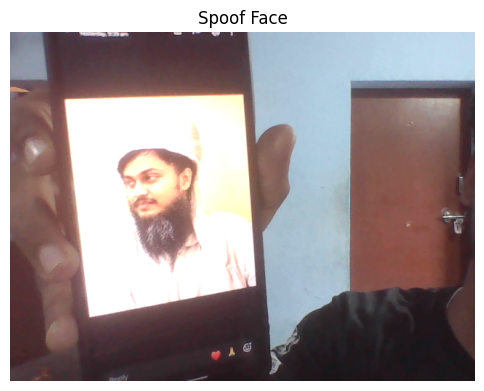

In [5]:
spoof_image = capture_image("Capture Spoof Face")

if spoof_image is not None:

    plt.figure(figsize=(6, 5))
    plt.imshow(cv2.cvtColor(spoof_image, cv2.COLOR_BGR2RGB))
    plt.title("Spoof Face")
    plt.axis("off");

In [6]:
def validate_face(image):

    faces = DeepFace.extract_faces(
        img_path=image,
        detector_backend="retinaface",
        align=True,
        anti_spoofing=True
    )

    results = []

    for face in faces:

        result = {
            "is_real": face["is_real"],
            "score": face["antispoof_score"],
            "facial_area": face["facial_area"]
        }

        results.append(result)

    return results

In [7]:
if original_image is None:
    raise ValueError("Original image was not captured")

original_results = validate_face(original_image)

print("ORIGINAL FACE RESULTS")
print("---------------------")

for i, result in enumerate(original_results):

    print(f"Face {i + 1}")
    print("Classification:", "REAL" if result["is_real"] else "SPOOF")
    print("Anti-spoof score:", result["score"])

ORIGINAL FACE RESULTS
---------------------
Face 1
Classification: REAL
Anti-spoof score: 0.9953604340553284


In [8]:
if spoof_image is None:
    raise ValueError("Spoof image was not captured")

spoof_results = validate_face(spoof_image)

print("SPOOF FACE RESULTS")
print("------------------")

for i, result in enumerate(spoof_results):

    print(f"Face {i + 1}")
    print("Classification:", "REAL" if result["is_real"] else "SPOOF")
    print("Anti-spoof score:", result["score"])

SPOOF FACE RESULTS
------------------
Face 1
Classification: SPOOF
Anti-spoof score: 0.9175416529178619


In [9]:
def visualize_result(image, results, title):

    output = image.copy()

    for result in results:

        area = result["facial_area"]

        x = area["x"]
        y = area["y"]
        w = area["w"]
        h = area["h"]

        is_real = result["is_real"]
        score = result["score"]

        if is_real:
            label = f"REAL | {score:.3f}"
            color = (0, 255, 0)
        else:
            label = f"SPOOF | {score:.3f}"
            color = (0, 0, 255)

        # Bounding box
        cv2.rectangle(
            output,
            (x, y),
            (x + w, y + h),
            color,
            2
        )

        # Classification label
        cv2.putText(
            output,
            label,
            (x, max(y - 10, 25)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            color,
            2
        )

    return output

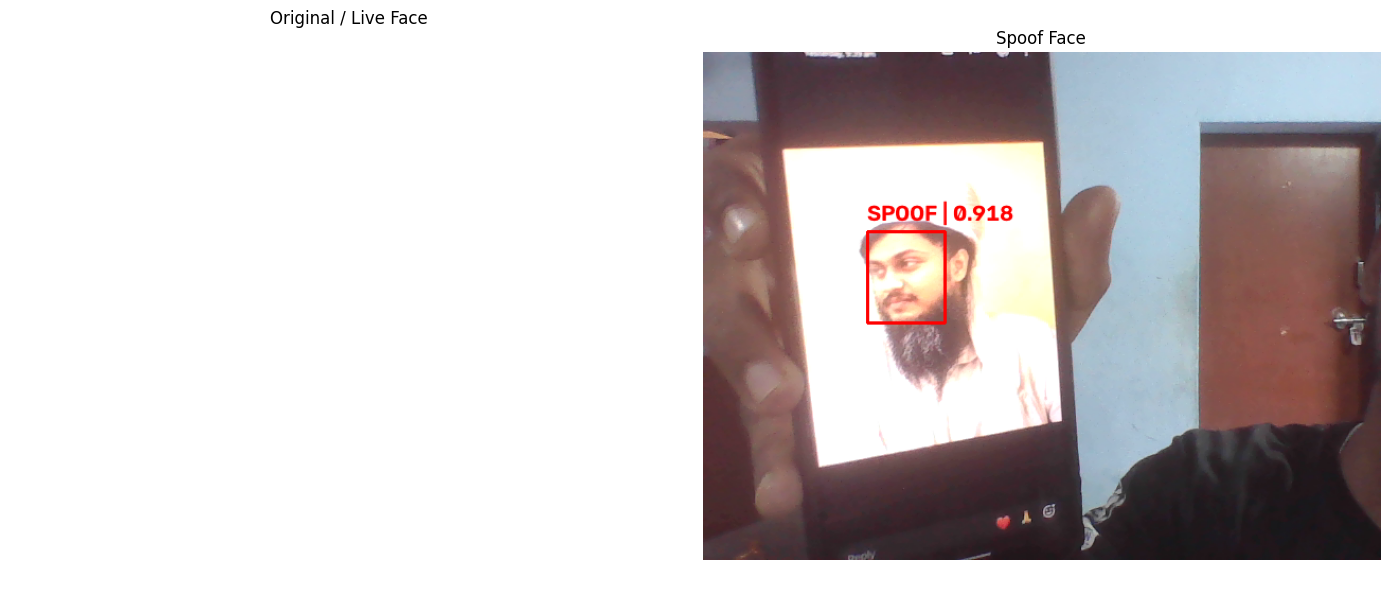

In [13]:
original_output = visualize_result(
    original_image,
    original_results,
    "Original"
)

spoof_output = visualize_result(
    spoof_image,
    spoof_results,
    "Spoof"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# axes[0].imshow(
#     cv2.cvtColor(original_output, cv2.COLOR_BGR2RGB)
# )
axes[0].set_title("Original / Live Face")
axes[0].axis("off")

axes[1].imshow(
    cv2.cvtColor(spoof_output, cv2.COLOR_BGR2RGB)
)
axes[1].set_title("Spoof Face")
axes[1].axis("off")

plt.tight_layout()
plt.show()